# # 02 — Quantitative Event Study

## Objectives
1. Prepare verified corporate event data.
2. Define estimation and event windows.
3. Estimate Market Model parameters (Alpha and Beta).
4. Calculate Expected Returns.
5. Calculate Abnormal Returns (AR).
6. Calculate Cumulative Abnormal Returns (CAR).
7. Calculate AAR and CAAR.
8. Perform statistical significance testing.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy import stats
from sklearn.linear_model import LinearRegression

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load processed market data
DATA_DIR = Path("../data/processed")

close_prices = pd.read_csv(
    DATA_DIR / "pilot_closing_prices.csv",
    index_col="Date",
    parse_dates=True
)

daily_returns = pd.read_csv(
    DATA_DIR / "pilot_daily_returns.csv",
    index_col="Date",
    parse_dates=True
)

print("Closing prices:", close_prices.shape)
print("Daily returns:", daily_returns.shape)

display(daily_returns.head())


Closing prices: (165, 4)
Daily returns: (165, 4)


,AAPL,MSFT,TSLA,SP500
Date,,,,
2025-01-02,NaN,NaN,NaN,NaN
2025-01-03,-0.2010,1.1396,8.2156,1.2596
2025-01-06,0.6739,1.0629,0.1486,0.5538
2025-01-07,-1.1388,-1.2808,-4.0603,-1.1104
2025-01-08,0.2023,0.5185,0.1471,0.1560


In [3]:

# Create an empty verified event dataset template

event_columns = [
    "event_id",
    "company",
    "event_date",
    "event_category",
    "headline",
    "source",
    "source_url"
]

events_df = pd.DataFrame(columns=event_columns)

print("Event dataset template created!")
display(events_df)


Event dataset template created!


,event_id,company,event_date,event_category,headline,source,source_url


In [4]:

events = [
    ["EV001", "AAPL", "2025-01-30", "Quarterly Earnings", "Apple reports first quarter results", "Apple IR", "https://www.apple.com/newsroom/2025/01/apple-reports-first-quarter-results/"],
    ["EV002", "AAPL", "2025-05-01", "Quarterly Earnings", "Apple reports second quarter results", "Apple IR", "https://www.apple.com/newsroom/2025/05/apple-reports-second-quarter-results/"],
    ["EV003", "AAPL", "2025-07-31", "Quarterly Earnings", "Apple reports third quarter results", "Apple IR", "https://www.apple.com/in/newsroom/2025/07/apple-reports-third-quarter-results/"],

    ["EV004", "MSFT", "2025-01-29", "Quarterly Earnings", "Microsoft FY2025 Q2 earnings", "Microsoft IR", "https://news.microsoft.com/source/2025/01/09/microsoft-announces-quarterly-earnings-release-date-62/"],
    ["EV005", "MSFT", "2025-04-30", "Quarterly Earnings", "Microsoft FY2025 Q3 earnings", "Microsoft IR", "https://www.sec.gov/Archives/edgar/data/789019/000095017025061032/msft-ex99_1.htm"],
    ["EV006", "MSFT", "2025-07-30", "Quarterly Earnings", "Microsoft FY2025 Q4 earnings", "Microsoft IR", "https://www.microsoft.com/en-us/Investor/earnings/FY-2025-Q4/press-release-webcast"],

    ["EV007", "TSLA", "2025-04-22", "Quarterly Earnings", "Tesla Q1 2025 earnings", "Tesla IR", "https://ir.tesla.com/"],
    ["EV008", "TSLA", "2025-07-23", "Quarterly Earnings", "Tesla Q2 2025 earnings", "Tesla IR", "https://ir.tesla.com/press-release/tesla-releases-second-quarter-2025-financial-results"]
]

events_df = pd.DataFrame(events, columns=event_columns)

events_df["event_date"] = pd.to_datetime(events_df["event_date"])

display(events_df)
print("Total verified event records:", len(events_df))


,event_id,company,event_date,event_category,headline,source,source_url
0,EV001,AAPL,2025-01-30,Quarterly Earnings,Apple reports first quarter results,Apple IR,https://www.apple.com/newsroom/2025/01/apple-r...
1,EV002,AAPL,2025-05-01,Quarterly Earnings,Apple reports second quarter results,Apple IR,https://www.apple.com/newsroom/2025/05/apple-r...
2,EV003,AAPL,2025-07-31,Quarterly Earnings,Apple reports third quarter results,Apple IR,https://www.apple.com/in/newsroom/2025/07/appl...
3,EV004,MSFT,2025-01-29,Quarterly Earnings,Microsoft FY2025 Q2 earnings,Microsoft IR,https://news.microsoft.com/source/2025/01/09/m...
4,EV005,MSFT,2025-04-30,Quarterly Earnings,Microsoft FY2025 Q3 earnings,Microsoft IR,https://www.sec.gov/Archives/edgar/data/789019...
5,EV006,MSFT,2025-07-30,Quarterly Earnings,Microsoft FY2025 Q4 earnings,Microsoft IR,https://www.microsoft.com/en-us/Investor/earni...
6,EV007,TSLA,2025-04-22,Quarterly Earnings,Tesla Q1 2025 earnings,Tesla IR,https://ir.tesla.com/
7,EV008,TSLA,2025-07-23,Quarterly Earnings,Tesla Q2 2025 earnings,Tesla IR,https://ir.tesla.com/press-release/tesla-relea...


Total verified event records: 8


In [5]:

# Map announcement dates to the next available trading session
trading_dates = close_prices.index.sort_values()

def get_reaction_date(event_date):
    event_date = pd.Timestamp(event_date)

    # First trading date strictly after announcement date
    future_dates = trading_dates[trading_dates > event_date]

    if len(future_dates) == 0:
        return pd.NaT

    return future_dates[0]

events_df["reaction_date"] = events_df["event_date"].apply(
    get_reaction_date
)

display(
    events_df[
        ["event_id", "company", "event_date", "reaction_date"]
    ]
)


,event_id,company,event_date,reaction_date
0,EV001,AAPL,2025-01-30,2025-01-31
1,EV002,AAPL,2025-05-01,2025-05-02
2,EV003,AAPL,2025-07-31,2025-08-01
3,EV004,MSFT,2025-01-29,2025-01-30
4,EV005,MSFT,2025-04-30,2025-05-01
5,EV006,MSFT,2025-07-30,2025-07-31
6,EV007,TSLA,2025-04-22,2025-04-23
7,EV008,TSLA,2025-07-23,2025-07-24


In [6]:

# Event study configuration

ESTIMATION_START = -120
ESTIMATION_END = -21

EVENT_START = -10
EVENT_END = 10

GAP_START = -20
GAP_END = -11

print("Estimation Window:", ESTIMATION_START, "to", ESTIMATION_END)
print("Gap Window:", GAP_START, "to", GAP_END)
print("Event Window:", EVENT_START, "to", EVENT_END)


Estimation Window: -120 to -21
Gap Window: -20 to -11
Event Window: -10 to 10


In [7]:
# Check available estimation-window observations for each event

trading_dates = close_prices.index.sort_values()

def count_estimation_observations(reaction_date):
    reaction_date = pd.Timestamp(reaction_date)

    event_position = trading_dates.get_indexer([reaction_date])[0]

    if event_position == -1:
        return 0

    start_position = event_position + ESTIMATION_START
    end_position = event_position + ESTIMATION_END

    start_position = max(0, start_position)
    end_position = min(len(trading_dates) - 1, end_position)

    if start_position > end_position:
        return 0

    return end_position - start_position + 1


events_df["available_estimation_days"] = (
    events_df["reaction_date"].apply(count_estimation_observations)
)

display(
    events_df[
        ["event_id", "company", "reaction_date", "available_estimation_days"]
    ]
)

,event_id,company,reaction_date,available_estimation_days
0,EV001,AAPL,2025-01-31,0
1,EV002,AAPL,2025-05-02,62
2,EV003,AAPL,2025-08-01,100
3,EV004,MSFT,2025-01-30,0
4,EV005,MSFT,2025-05-01,61
5,EV006,MSFT,2025-07-31,100
6,EV007,TSLA,2025-04-23,55
7,EV008,TSLA,2025-07-24,100


In [8]:
import yfinance as yf

tickers = ["AAPL", "MSFT", "TSLA", "^GSPC"]

historical_data = yf.download(
    tickers,
    start="2024-07-01",
    end="2025-09-01",
    auto_adjust=True,
    progress=False
)

# Extract adjusted closing prices
close_prices = historical_data["Close"].copy()

# Rename benchmark column
close_prices = close_prices.rename(columns={"^GSPC": "SP500"})

# Sort dates and remove rows where all prices are missing
close_prices = close_prices.sort_index().dropna(how="all")

# Calculate daily percentage returns
daily_returns = close_prices.pct_change() * 100

# Save updated datasets
close_prices.to_csv(DATA_DIR / "pilot_closing_prices.csv")
daily_returns.to_csv(DATA_DIR / "pilot_daily_returns.csv")

print("Closing prices shape:", close_prices.shape)
print("Daily returns shape:", daily_returns.shape)
print("Start date:", close_prices.index.min())
print("End date:", close_prices.index.max())

display(close_prices.head())

Closing prices shape: (293, 4)
Daily returns shape: (293, 4)
Start date: 2024-07-01 00:00:00
End date: 2025-08-29 00:00:00


Ticker,AAPL,MSFT,TSLA,SP500
Date,,,,
2024-07-01,214.7033,448.8184,209.8600,5475.0898
2024-07-02,218.1902,451.3241,231.2600,5509.0098
2024-07-03,219.4580,452.7884,246.3900,5537.0200
2024-07-05,224.2028,459.4607,251.5200,5567.1899
2024-07-08,225.6689,458.1635,252.9400,5572.8501


In [9]:
# Recheck estimation-window observations after extending historical data

trading_dates = close_prices.index.sort_values()

events_df["available_estimation_days"] = (
    events_df["reaction_date"].apply(count_estimation_observations)
)

display(
    events_df[
        ["event_id", "company", "reaction_date", "available_estimation_days"]
    ]
)

,event_id,company,reaction_date,available_estimation_days
0,EV001,AAPL,2025-01-31,100
1,EV002,AAPL,2025-05-02,100
2,EV003,AAPL,2025-08-01,100
3,EV004,MSFT,2025-01-30,100
4,EV005,MSFT,2025-05-01,100
5,EV006,MSFT,2025-07-31,100
6,EV007,TSLA,2025-04-23,100
7,EV008,TSLA,2025-07-24,100


In [10]:
# Calculate Alpha and Beta for each event

market_model_results = []

for _, event in events_df.iterrows():

    company = event["company"]
    reaction_date = pd.Timestamp(event["reaction_date"])

    # Find event position in trading calendar
    event_position = trading_dates.get_loc(reaction_date)

    # Estimation window: -120 to -21
    estimation_dates = trading_dates[
        event_position + ESTIMATION_START:
        event_position + ESTIMATION_END + 1
    ]

    # Select stock and market returns
    estimation_data = daily_returns.loc[
        estimation_dates, [company, "SP500"]
    ].dropna()

    X = estimation_data[["SP500"]]
    y = estimation_data[company]

    # Fit Market Model
    model = LinearRegression()
    model.fit(X, y)

    alpha = model.intercept_
    beta = model.coef_[0]
    r_squared = model.score(X, y)

    market_model_results.append({
        "event_id": event["event_id"],
        "company": company,
        "reaction_date": reaction_date,
        "observations": len(estimation_data),
        "alpha": alpha,
        "beta": beta,
        "r_squared": r_squared
    })

market_model_df = pd.DataFrame(market_model_results)

display(market_model_df.round(4))

,event_id,company,reaction_date,observations,alpha,beta,r_squared
0,EV001,AAPL,2025-01-31,100,0.0902,0.7841,0.3179
1,EV002,AAPL,2025-05-02,100,0.0284,0.8238,0.2610
2,EV003,AAPL,2025-08-01,100,-0.1070,1.4064,0.7413
3,EV004,MSFT,2025-01-30,100,-0.0585,1.0786,0.5200
4,EV005,MSFT,2025-05-01,100,-0.0418,1.0429,0.4636
5,EV006,MSFT,2025-07-31,100,0.1618,0.9259,0.6908
6,EV007,TSLA,2025-04-23,100,0.1466,3.2140,0.4426
7,EV008,TSLA,2025-07-24,100,-0.0556,2.3224,0.5630


In [11]:
# Calculate Expected Returns and Abnormal Returns

abnormal_returns_list = []

for _, event in market_model_df.iterrows():

    event_id = event["event_id"]
    company = event["company"]
    reaction_date = pd.Timestamp(event["reaction_date"])

    event_position = trading_dates.get_loc(reaction_date)

    # Event window: -10 to +10
    event_dates = trading_dates[
        event_position + EVENT_START:
        event_position + EVENT_END + 1
    ]

    event_data = daily_returns.loc[
        event_dates, [company, "SP500"]
    ].copy()

    event_data["event_id"] = event_id
    event_data["company"] = company

    # Relative event time
    event_data["event_time"] = np.arange(
        EVENT_START, EVENT_END + 1
    )

    # Expected and abnormal returns
    event_data["expected_return"] = (
        event["alpha"] +
        event["beta"] * event_data["SP500"]
    )

    event_data["abnormal_return"] = (
        event_data[company] - event_data["expected_return"]
    )

    abnormal_returns_list.append(event_data.reset_index())

abnormal_returns_df = pd.concat(
    abnormal_returns_list,
    ignore_index=True
)

display(abnormal_returns_df.head(10).round(4))
print("Total event observations:", len(abnormal_returns_df))

Ticker,Date,AAPL,SP500,event_id,company,event_time,expected_return,abnormal_return,MSFT,TSLA
0,2025-01-16,-4.0400,-0.2113,EV001,AAPL,-10,-0.0754,-3.9646,NaN,NaN
1,2025-01-17,0.7535,0.9991,EV001,AAPL,-9,0.8737,-0.1201,NaN,NaN
2,2025-01-21,-3.1916,0.8768,EV001,AAPL,-8,0.7778,-3.9693,NaN,NaN
3,2025-01-22,0.5345,0.6138,EV001,AAPL,-7,0.5715,-0.0370,NaN,NaN
4,2025-01-23,-0.0760,0.5313,EV001,AAPL,-6,0.5069,-0.5828,NaN,NaN
5,2025-01-24,-0.3934,-0.2855,EV001,AAPL,-5,-0.1336,-0.2598,NaN,NaN
6,2025-01-27,3.1780,-1.4581,EV001,AAPL,-4,-1.0530,4.2310,NaN,NaN
7,2025-01-28,3.6544,0.9218,EV001,AAPL,-3,0.8130,2.8414,NaN,NaN
8,2025-01-29,0.4617,-0.4679,EV001,AAPL,-2,-0.2766,0.7383,NaN,NaN
9,2025-01-30,-0.7395,0.5275,EV001,AAPL,-1,0.5039,-1.2434,NaN,NaN


Total event observations: 168


In [12]:
# Calculate Cumulative Abnormal Returns (CAR)

abnormal_returns_df = abnormal_returns_df.sort_values(
    ["event_id", "event_time"]
)

abnormal_returns_df["CAR"] = (
    abnormal_returns_df
    .groupby("event_id")["abnormal_return"]
    .cumsum()
)

# Display CAR for all events
display(
    abnormal_returns_df[
        ["event_id", "company", "event_time",
         "abnormal_return", "CAR"]
    ].round(4).head(25)
)

# Final CAR for each event over the complete event window
event_car_summary = (
    abnormal_returns_df
    .groupby(["event_id", "company"])
    .agg(
        total_CAR=("abnormal_return", "sum"),
        average_AR=("abnormal_return", "mean"),
        max_CAR=("CAR", "max"),
        min_CAR=("CAR", "min")
    )
    .reset_index()
)

display(event_car_summary.round(4))

Ticker,event_id,company,event_time,abnormal_return,CAR
0,EV001,AAPL,-10,-3.9646,-3.9646
1,EV001,AAPL,-9,-0.1201,-4.0847
2,EV001,AAPL,-8,-3.9693,-8.0541
3,EV001,AAPL,-7,-0.0370,-8.0911
4,EV001,AAPL,-6,-0.5828,-8.6739
5,EV001,AAPL,-5,-0.2598,-8.9338
6,EV001,AAPL,-4,4.2310,-4.7027
7,EV001,AAPL,-3,2.8414,-1.8614
8,EV001,AAPL,-2,0.7383,-1.1230
9,EV001,AAPL,-1,-1.2434,-2.3664


,event_id,company,total_CAR,average_AR,max_CAR,min_CAR
0,EV001,AAPL,-0.7374,-0.0351,-0.7374,-8.9338
1,EV002,AAPL,-1.7841,-0.0850,4.3113,-4.5871
2,EV003,AAPL,9.0547,0.4312,9.2228,-2.6528
3,EV004,MSFT,-4.5795,-0.2181,3.9070,-4.5795
4,EV005,MSFT,7.9157,0.3769,8.9929,-2.6978
5,EV006,MSFT,-2.9642,-0.1412,2.7964,-3.1393
6,EV007,TSLA,-18.6953,-0.8903,0.0000,-18.6953
7,EV008,TSLA,7.6957,0.3665,10.5892,0.6625


In [13]:
# Calculate Average Abnormal Return (AAR)

aar_df = (
    abnormal_returns_df
    .groupby("event_time")["abnormal_return"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

aar_df = aar_df.rename(columns={
    "mean": "AAR",
    "std": "std_AR",
    "count": "number_of_events"
})

# Calculate Cumulative Average Abnormal Return (CAAR)

aar_df["CAAR"] = aar_df["AAR"].cumsum()

display(aar_df.round(4))

,event_time,AAR,std_AR,number_of_events,CAAR
0,-10,0.2519,2.2924,8,0.2519
1,-9,-0.9232,3.0140,8,-0.6713
2,-8,0.3321,2.1348,8,-0.3392
3,-7,-1.2089,2.0715,8,-1.5481
4,-6,0.3314,1.9936,8,-1.2167
5,-5,0.0121,1.0500,8,-1.2045
6,-4,1.2953,1.6947,8,0.0908
7,-3,-0.0404,1.1915,8,0.0504
8,-2,0.6742,0.8861,8,0.7246
9,-1,-0.8713,1.2842,8,-0.1467


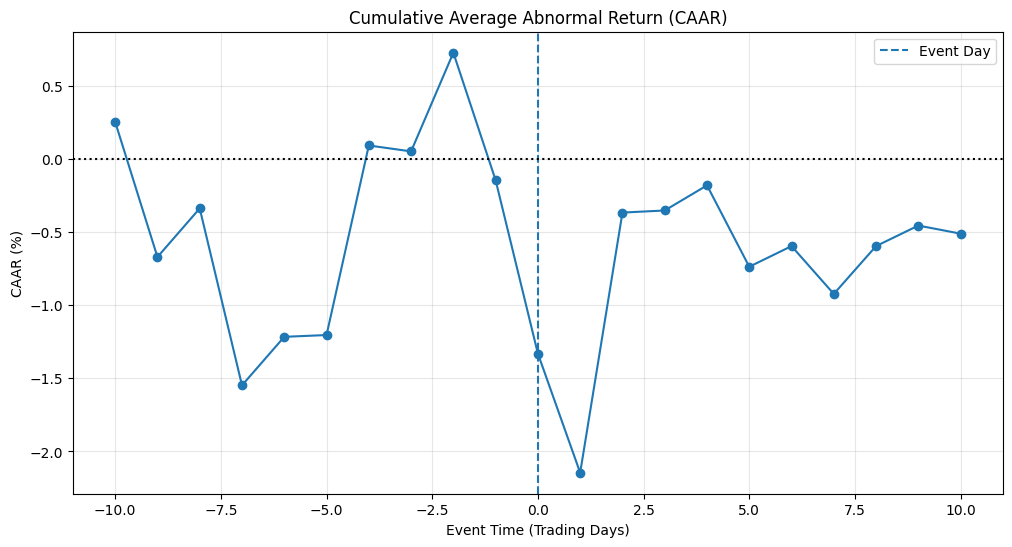

In [14]:
plt.figure(figsize=(12, 6))

plt.plot(
    aar_df["event_time"],
    aar_df["CAAR"],
    marker="o"
)

plt.axvline(x=0, linestyle="--", label="Event Day")
plt.axhline(y=0, linestyle=":", color="black")

plt.title("Cumulative Average Abnormal Return (CAAR)")
plt.xlabel("Event Time (Trading Days)")
plt.ylabel("CAAR (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [15]:
# Statistical Significance Testing of Event-window CAR

event_windows = {
    "[-1, +1]": (-1, 1),
    "[0, +1]": (0, 1),
    "[-5, +5]": (-5, 5),
    "[-10, +10]": (-10, 10)
}

significance_results = []

for window_name, (start, end) in event_windows.items():

    # Calculate CAR separately for each event
    window_car = (
        abnormal_returns_df[
            abnormal_returns_df["event_time"].between(start, end)
        ]
        .groupby(["event_id", "company"])["abnormal_return"]
        .sum()
    )

    # One-sample t-test against zero
    t_stat, p_value = stats.ttest_1samp(
        window_car,
        popmean=0
    )

    n = len(window_car)
    mean_car = window_car.mean()
    std_car = window_car.std(ddof=1)

    # 95% confidence interval
    standard_error = std_car / np.sqrt(n)
    margin = stats.t.ppf(0.975, df=n-1) * standard_error

    significance_results.append({
        "event_window": window_name,
        "number_of_events": n,
        "mean_CAR": mean_car,
        "std_CAR": std_car,
        "t_statistic": t_stat,
        "p_value": p_value,
        "CI_lower": mean_car - margin,
        "CI_upper": mean_car + margin
    })

significance_df = pd.DataFrame(significance_results)

display(significance_df.round(4))

,event_window,number_of_events,mean_CAR,std_CAR,t_statistic,p_value,CI_lower,CI_upper
0,"[-1, +1]",8,-2.8698,5.8648,-1.3841,0.2089,-7.7729,2.0332
1,"[0, +1]",8,-1.9985,5.2648,-1.0737,0.3186,-6.4000,2.4029
2,"[-5, +5]",8,0.4788,6.7690,0.2001,0.8471,-5.1802,6.1378
3,"[-10, +10]",8,-0.5118,9.1399,-0.1584,0.8786,-8.1530,7.1294


In [16]:
# Wilcoxon Signed-Rank Test

wilcoxon_results = []

for window_name, (start, end) in event_windows.items():

    window_car = (
        abnormal_returns_df[
            abnormal_returns_df["event_time"].between(start, end)
        ]
        .groupby("event_id")["abnormal_return"]
        .sum()
    )

    # Wilcoxon test against zero
    test_stat, p_value = stats.wilcoxon(
        window_car,
        alternative="two-sided"
    )

    wilcoxon_results.append({
        "event_window": window_name,
        "median_CAR": window_car.median(),
        "wilcoxon_statistic": test_stat,
        "p_value": p_value
    })

wilcoxon_df = pd.DataFrame(wilcoxon_results)

display(wilcoxon_df.round(4))

,event_window,median_CAR,wilcoxon_statistic,p_value
0,"[-1, +1]",-5.5419,10.0000,0.3125
1,"[0, +1]",-3.2692,12.0000,0.4609
2,"[-5, +5]",1.1306,15.0000,0.7422
3,"[-10, +10]",-1.2607,18.0000,1.0000


In [17]:
# Company-wise CAR comparison across event windows

company_comparison = []

for window_name, (start, end) in event_windows.items():

    window_data = abnormal_returns_df[
        abnormal_returns_df["event_time"].between(start, end)
    ]

    # Calculate CAR for each event
    event_car = (
        window_data
        .groupby(["event_id", "company"])["abnormal_return"]
        .sum()
        .reset_index(name="CAR")
    )

    # Aggregate events by company
    company_summary = (
        event_car
        .groupby("company")["CAR"]
        .agg(["mean", "median", "std", "count"])
        .reset_index()
    )

    company_summary["event_window"] = window_name

    company_comparison.append(company_summary)

company_comparison_df = pd.concat(
    company_comparison,
    ignore_index=True
)

company_comparison_df = company_comparison_df.rename(columns={
    "mean": "mean_CAR",
    "median": "median_CAR",
    "std": "std_CAR",
    "count": "number_of_events"
})

display(company_comparison_df.round(4))

,company,mean_CAR,median_CAR,std_CAR,number_of_events,event_window
0,AAPL,-4.6620,-4.4864,3.0417,3,"[-1, +1]"
1,MSFT,1.7365,3.7713,7.5257,3,"[-1, +1]"
2,TSLA,-7.0911,-7.0911,0.2527,2,"[-1, +1]"
3,AAPL,-4.1666,-3.2430,3.1027,3,"[0, +1]"
4,MSFT,1.8179,3.6867,7.1409,3,"[0, +1]"
5,TSLA,-4.4710,-4.4710,1.6625,2,"[0, +1]"
6,AAPL,0.8188,2.1717,7.8522,3,"[-5, +5]"
7,MSFT,2.1645,1.5224,8.6115,3,"[-5, +5]"
8,TSLA,-2.5598,-2.5598,4.6648,2,"[-5, +5]"
9,AAPL,2.1777,-0.7374,5.9785,3,"[-10, +10]"


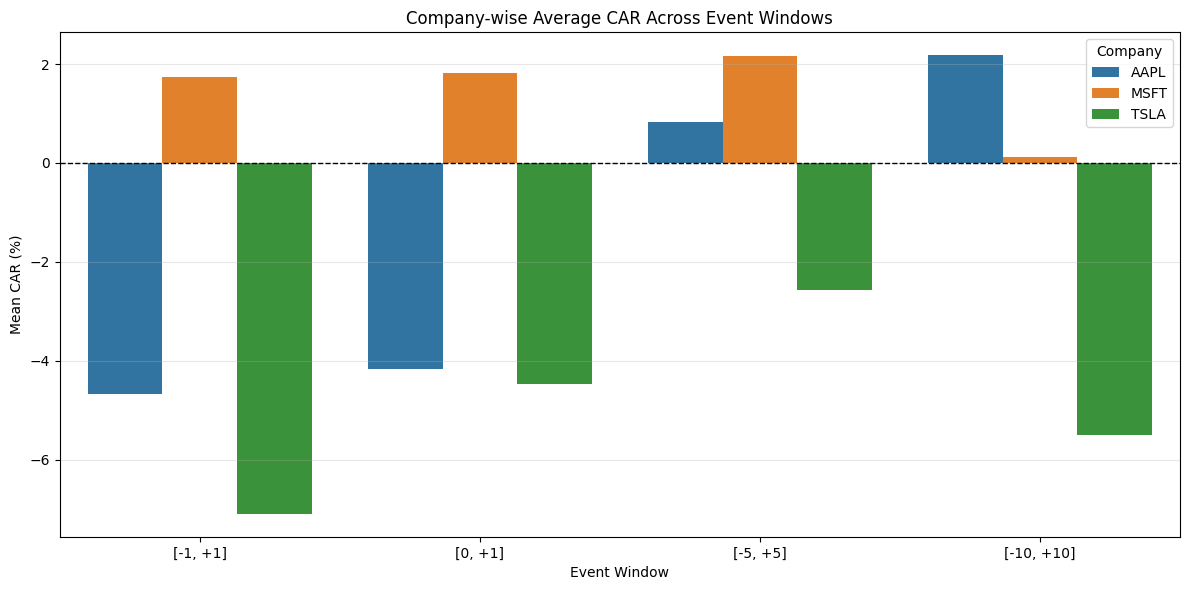

In [18]:
# Company-wise CAR comparison plot

plt.figure(figsize=(12, 6))

sns.barplot(
    data=company_comparison_df,
    x="event_window",
    y="mean_CAR",
    hue="company"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Company-wise Average CAR Across Event Windows")
plt.xlabel("Event Window")
plt.ylabel("Mean CAR (%)")
plt.legend(title="Company")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# Event-wise volatility analysis

volatility_results = []

periods = {
    "Pre_Event": (-10, -1),
    "Post_Event": (0, 10),
    "Complete_Event": (-10, 10)
}

for _, event in events_df.iterrows():

    event_id = event["event_id"]
    company = event["company"]

    event_data = abnormal_returns_df[
        abnormal_returns_df["event_id"] == event_id
    ]

    for period_name, (start, end) in periods.items():

        period_data = event_data[
            event_data["event_time"].between(start, end)
        ]

        actual_volatility = period_data[company].std()
        abnormal_volatility = period_data["abnormal_return"].std()

        volatility_results.append({
            "event_id": event_id,
            "company": company,
            "period": period_name,
            "actual_return_volatility": actual_volatility,
            "abnormal_return_volatility": abnormal_volatility
        })

volatility_df = pd.DataFrame(volatility_results)

display(volatility_df.round(4))

,event_id,company,period,actual_return_volatility,abnormal_return_volatility
0,EV001,AAPL,Pre_Event,2.3976,2.5691
1,EV001,AAPL,Post_Event,1.8673,1.5638
2,EV001,AAPL,Complete_Event,2.0857,2.0571
3,EV002,AAPL,Pre_Event,1.4437,0.5817
4,EV002,AAPL,Post_Event,2.5885,2.1403
5,EV002,AAPL,Complete_Event,2.1325,1.6375
6,EV003,AAPL,Pre_Event,0.7239,0.6758
7,EV003,AAPL,Post_Event,2.3125,1.8640
8,EV003,AAPL,Complete_Event,1.8044,1.4880
9,EV004,MSFT,Pre_Event,1.9825,1.3899


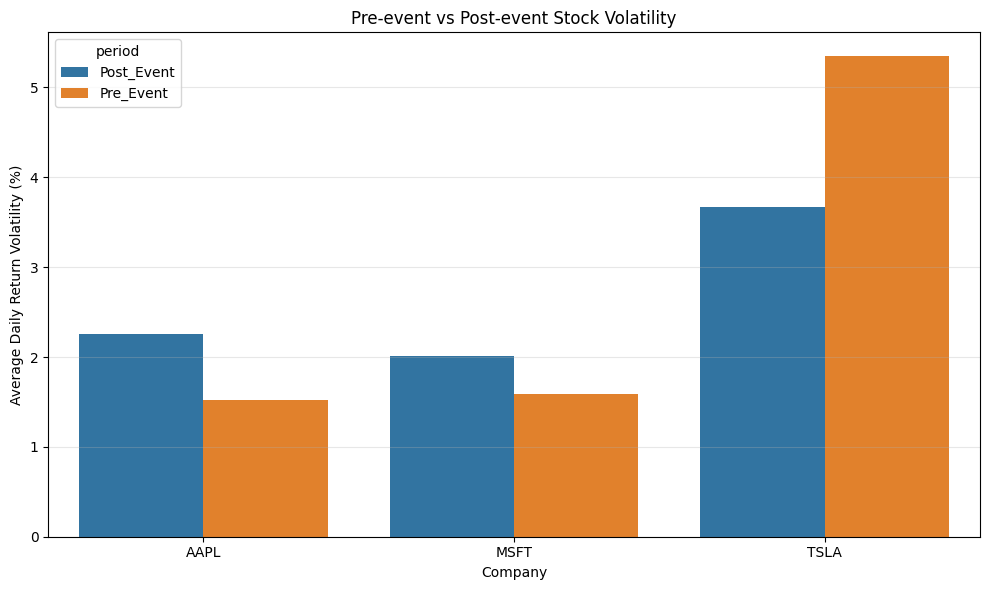

,company,period,actual_return_volatility
0,AAPL,Post_Event,2.2561
1,AAPL,Pre_Event,1.5217
2,MSFT,Post_Event,2.0090
3,MSFT,Pre_Event,1.5919
4,TSLA,Post_Event,3.6681
5,TSLA,Pre_Event,5.3465


In [20]:
# Company-wise pre-event vs post-event volatility

volatility_comparison = (
    volatility_df[
        volatility_df["period"].isin(["Pre_Event", "Post_Event"])
    ]
    .groupby(["company", "period"])["actual_return_volatility"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=volatility_comparison,
    x="company",
    y="actual_return_volatility",
    hue="period"
)

plt.title("Pre-event vs Post-event Stock Volatility")
plt.xlabel("Company")
plt.ylabel("Average Daily Return Volatility (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(volatility_comparison.round(4))

In [21]:
# Paired volatility comparison for each event

volatility_pivot = volatility_df.pivot(
    index=["event_id", "company"],
    columns="period",
    values="actual_return_volatility"
).reset_index()

volatility_pivot["volatility_change"] = (
    volatility_pivot["Post_Event"] -
    volatility_pivot["Pre_Event"]
)

# Paired t-test
t_stat, t_pvalue = stats.ttest_rel(
    volatility_pivot["Post_Event"],
    volatility_pivot["Pre_Event"]
)

# Wilcoxon signed-rank test
w_stat, w_pvalue = stats.wilcoxon(
    volatility_pivot["Post_Event"],
    volatility_pivot["Pre_Event"]
)

print("Mean Pre-event Volatility:",
      volatility_pivot["Pre_Event"].mean().round(4))

print("Mean Post-event Volatility:",
      volatility_pivot["Post_Event"].mean().round(4))

print("Mean Volatility Change:",
      volatility_pivot["volatility_change"].mean().round(4))

print("\nPaired t-test")
print("T-statistic:", round(t_stat, 4))
print("P-value:", round(t_pvalue, 4))

print("\nWilcoxon Signed-Rank Test")
print("Statistic:", round(w_stat, 4))
print("P-value:", round(w_pvalue, 4))

display(volatility_pivot.round(4))

Mean Pre-event Volatility: 2.5042
Mean Post-event Volatility: 2.5164
Mean Volatility Change: 0.0122

Paired t-test
T-statistic: 0.0165
P-value: 0.9873

Wilcoxon Signed-Rank Test
Statistic: 12.0
P-value: 0.4609


period,event_id,company,Complete_Event,Post_Event,Pre_Event,volatility_change
0,EV001,AAPL,2.0857,1.8673,2.3976,-0.5303
1,EV002,AAPL,2.1325,2.5885,1.4437,1.1448
2,EV003,AAPL,1.8044,2.3125,0.7239,1.5885
3,EV004,MSFT,2.0273,1.9492,1.9825,-0.0333
4,EV005,MSFT,2.2481,2.3127,2.1628,0.1499
5,EV006,MSFT,1.3179,1.7651,0.6304,1.1347
6,EV007,TSLA,6.3981,3.8196,8.6175,-4.7979
7,EV008,TSLA,2.9413,3.5165,2.0755,1.4410


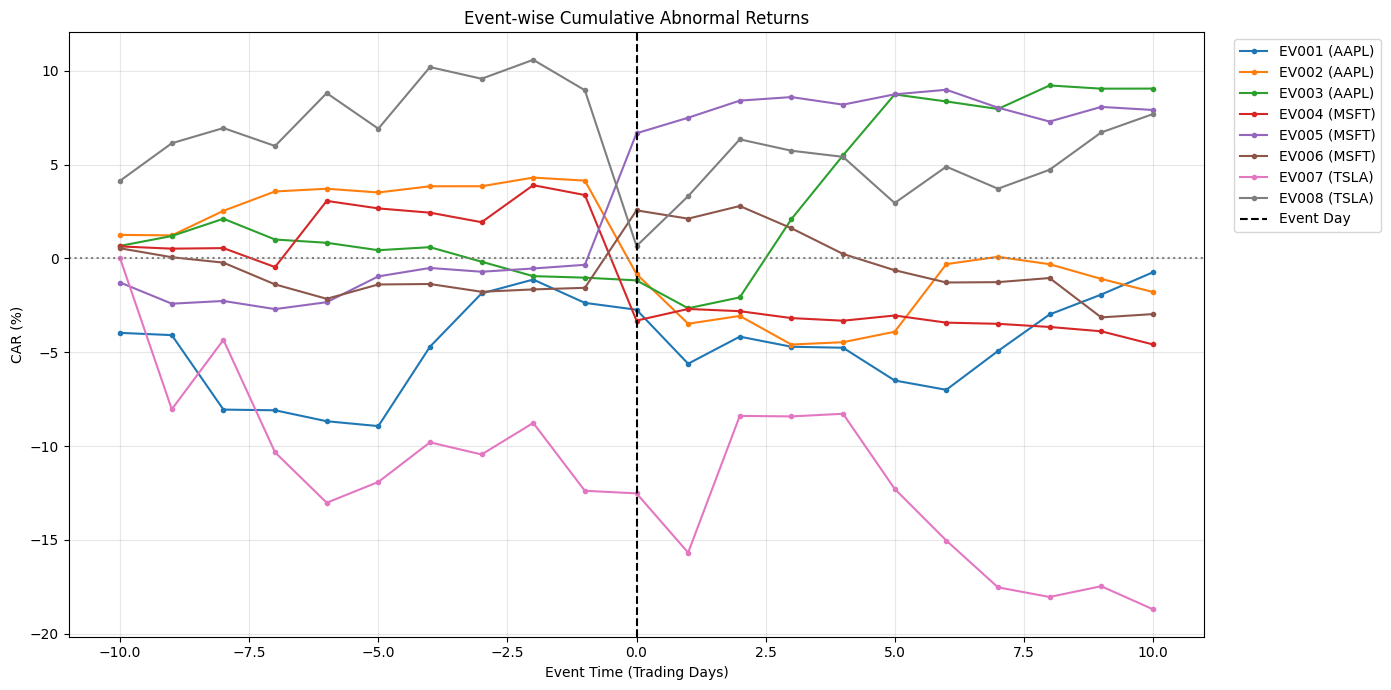

In [22]:
# Plot event-wise Cumulative Abnormal Returns

plt.figure(figsize=(14, 7))

for event_id, group in abnormal_returns_df.groupby("event_id"):

    company = group["company"].iloc[0]

    plt.plot(
        group["event_time"],
        group["CAR"],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=f"{event_id} ({company})"
    )

plt.axvline(0, color="black", linestyle="--", label="Event Day")
plt.axhline(0, color="gray", linestyle=":")

plt.title("Event-wise Cumulative Abnormal Returns")
plt.xlabel("Event Time (Trading Days)")
plt.ylabel("CAR (%)")

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
# Prepare event-window CAR matrix

window_car_matrix = pd.DataFrame(index=events_df["event_id"])

window_car_matrix.index.name = "event_id"

for window_name, (start, end) in event_windows.items():

    window_car = (
        abnormal_returns_df[
            abnormal_returns_df["event_time"].between(start, end)
        ]
        .groupby("event_id")["abnormal_return"]
        .sum()
    )

    window_car_matrix[window_name] = window_car

# Add company names
company_mapping = events_df.set_index("event_id")["company"]

window_car_matrix["company"] = company_mapping

display(window_car_matrix.round(4))

,"[-1, +1]","[0, +1]","[-5, +5]","[-10, +10]",company
event_id,,,,,
EV001,-4.4864,-3.2430,2.1717,-0.7374,AAPL
EV002,-7.7877,-7.6263,-7.6220,-1.7841,AAPL
EV003,-1.7120,-1.6306,7.9066,9.0547,AAPL
EV004,-6.5974,-6.0716,-6.1080,-4.5795,MSFT
EV005,8.0356,7.8386,11.0791,7.9157,MSFT
EV006,3.7713,3.6867,1.5224,-2.9642,MSFT
EV007,-6.9124,-3.2954,0.7387,-18.6953,TSLA
EV008,-7.2698,-5.6466,-5.8584,7.6957,TSLA


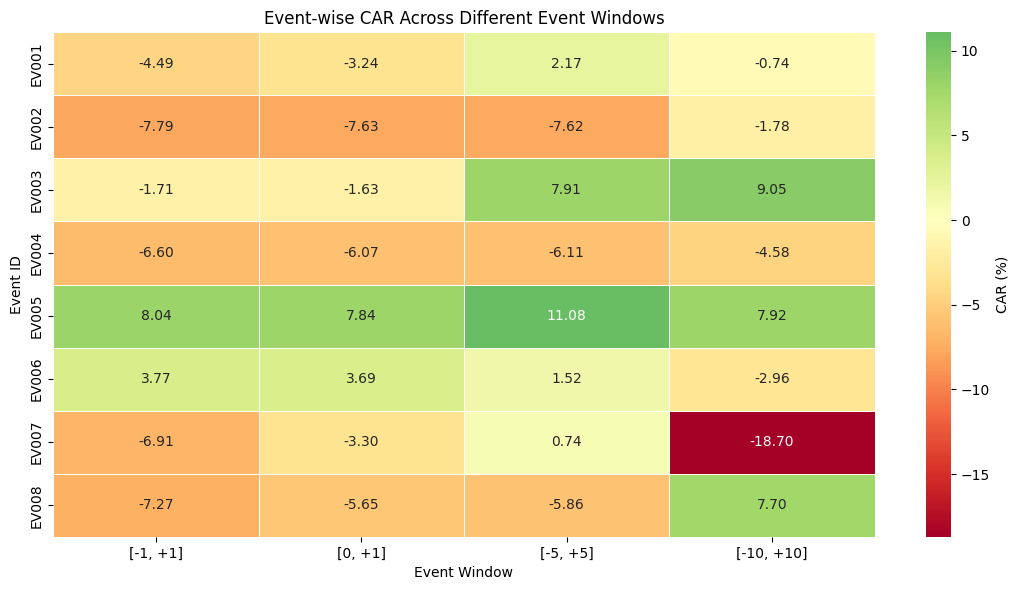

In [24]:
# Event-window CAR Heatmap

plt.figure(figsize=(11, 6))

heatmap_data = window_car_matrix.drop(columns="company")

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "CAR (%)"}
)

plt.title("Event-wise CAR Across Different Event Windows")
plt.xlabel("Event Window")
plt.ylabel("Event ID")

plt.tight_layout()
plt.show()

In [25]:
# Export quantitative event-study results

RESULTS_DIR = Path("../data/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

market_model_df.to_csv(
    RESULTS_DIR / "market_model_results.csv", index=False
)

abnormal_returns_df.to_csv(
    RESULTS_DIR / "abnormal_returns.csv", index=False
)

event_car_summary.to_csv(
    RESULTS_DIR / "event_car_summary.csv", index=False
)

aar_df.to_csv(
    RESULTS_DIR / "aar_caar_results.csv", index=False
)

significance_df.to_csv(
    RESULTS_DIR / "t_test_results.csv", index=False
)

wilcoxon_df.to_csv(
    RESULTS_DIR / "wilcoxon_results.csv", index=False
)

company_comparison_df.to_csv(
    RESULTS_DIR / "company_car_comparison.csv", index=False
)

volatility_df.to_csv(
    RESULTS_DIR / "volatility_results.csv", index=False
)

volatility_pivot.to_csv(
    RESULTS_DIR / "volatility_comparison.csv", index=False
)

window_car_matrix.to_csv(
    RESULTS_DIR / "event_window_car_matrix.csv"
)

events_df.to_csv(
    RESULTS_DIR / "pilot_events.csv", index=False
)

print("All quantitative event-study results exported successfully!")
print("Saved in:", RESULTS_DIR.resolve())

All quantitative event-study results exported successfully!
Saved in: C:\Users\Victus\OneDrive\Desktop\EventEcho_streamlit\data\results


In [26]:
# Update event verification metadata

verified_events = {
    "EV001": {
        "timing": "After market close",
        "url": "https://www.apple.com/newsroom/2025/01/apple-reports-first-quarter-results/"
    },
    "EV002": {
        "timing": "After market close",
        "url": "https://www.apple.com/newsroom/2025/05/apple-reports-second-quarter-results/"
    },
    "EV003": {
        "timing": "After market close",
        "url": "https://www.apple.com/in/newsroom/2025/07/apple-reports-third-quarter-results/"
    },
    "EV004": {
        "timing": "After market close",
        "url": "https://www.microsoft.com/en-us/investor/earnings/fy-2025-q2/press-release-webcast"
    },
    "EV005": {
        "timing": "After market close",
        "url": "https://www.microsoft.com/en-us/investor/earnings/fy-2025-q3/press-release-webcast"
    },
    "EV006": {
        "timing": "After market close",
        "url": "https://www.microsoft.com/en-us/investor/earnings/fy-2025-q4/press-release-webcast"
    },
    "EV007": {
        "timing": "After market close",
        "url": "https://ir.tesla.com/press-release/tesla-releases-first-quarter-2025-financial-results"
    },
    "EV008": {
        "timing": "After market close",
        "url": "https://ir.tesla.com/press-release/tesla-releases-second-quarter-2025-financial-results"
    }
}

events_df["announcement_timing"] = events_df["event_id"].map(
    lambda x: verified_events[x]["timing"]
)

events_df["source_url"] = events_df["event_id"].map(
    lambda x: verified_events[x]["url"]
)

events_df["verification_status"] = "Official source verified"

# Save verified event metadata
events_df.to_csv(
    RESULTS_DIR / "pilot_events.csv",
    index=False
)

display(
    events_df[
        ["event_id", "company", "event_date",
         "reaction_date", "announcement_timing",
         "verification_status"]
    ]
)

,event_id,company,event_date,reaction_date,announcement_timing,verification_status
0,EV001,AAPL,2025-01-30,2025-01-31,After market close,Official source verified
1,EV002,AAPL,2025-05-01,2025-05-02,After market close,Official source verified
2,EV003,AAPL,2025-07-31,2025-08-01,After market close,Official source verified
3,EV004,MSFT,2025-01-29,2025-01-30,After market close,Official source verified
4,EV005,MSFT,2025-04-30,2025-05-01,After market close,Official source verified
5,EV006,MSFT,2025-07-30,2025-07-31,After market close,Official source verified
6,EV007,TSLA,2025-04-22,2025-04-23,After market close,Official source verified
7,EV008,TSLA,2025-07-23,2025-07-24,After market close,Official source verified


In [27]:
# Final quantitative event-study validation

checks = {
    "Unique event IDs": events_df["event_id"].is_unique,
    "All event dates available": events_df["event_date"].notna().all(),
    "All reaction dates available": events_df["reaction_date"].notna().all(),
    "All events source verified": (
        events_df["verification_status"].eq("Official source verified").all()
    ),
    "All estimation windows have 100 observations": (
        market_model_df["observations"].eq(100).all()
    ),
    "All events have 21 event-window observations": (
        abnormal_returns_df.groupby("event_id").size().eq(21).all()
    ),
    "No missing abnormal returns": (
        abnormal_returns_df["abnormal_return"].notna().all()
    ),
    "No missing expected returns": (
        abnormal_returns_df["expected_return"].notna().all()
    ),
    "No missing CAR values": (
        abnormal_returns_df["CAR"].notna().all()
    )
}

validation_df = pd.DataFrame(
    list(checks.items()),
    columns=["Validation Check", "Passed"]
)

display(validation_df)

print(
    f"\nPassed: {sum(checks.values())}/{len(checks)}"
)

,Validation Check,Passed
0,Unique event IDs,True
1,All event dates available,True
2,All reaction dates available,True
3,All events source verified,True
4,All estimation windows have 100 observations,True
5,All events have 21 event-window observations,True
6,No missing abnormal returns,True
7,No missing expected returns,True
8,No missing CAR values,True



Passed: 9/9


In [28]:
# Create final event-study summary

final_event_summary = (
    market_model_df[
        ["event_id", "company", "alpha", "beta", "r_squared"]
    ]
    .merge(
        event_car_summary[
            ["event_id", "total_CAR", "average_AR"]
        ],
        on="event_id"
    )
    .merge(
        events_df[
            ["event_id", "event_date", "reaction_date",
             "event_category", "announcement_timing",
             "source_url", "verification_status"]
        ],
        on="event_id"
    )
)

# Reorder columns
final_event_summary = final_event_summary[
    [
        "event_id", "company", "event_date", "reaction_date",
        "event_category", "alpha", "beta", "r_squared",
        "total_CAR", "average_AR", "announcement_timing",
        "verification_status", "source_url"
    ]
]

display(final_event_summary.round(4))

# Export final summary
final_event_summary.to_csv(
    RESULTS_DIR / "final_event_study_summary.csv",
    index=False
)

print("Final event-study summary saved successfully!")

,event_id,company,event_date,reaction_date,event_category,alpha,beta,r_squared,total_CAR,average_AR,announcement_timing,verification_status,source_url
0,EV001,AAPL,2025-01-30,2025-01-31,Quarterly Earnings,0.0902,0.7841,0.3179,-0.7374,-0.0351,After market close,Official source verified,https://www.apple.com/newsroom/2025/01/apple-r...
1,EV002,AAPL,2025-05-01,2025-05-02,Quarterly Earnings,0.0284,0.8238,0.2610,-1.7841,-0.0850,After market close,Official source verified,https://www.apple.com/newsroom/2025/05/apple-r...
2,EV003,AAPL,2025-07-31,2025-08-01,Quarterly Earnings,-0.1070,1.4064,0.7413,9.0547,0.4312,After market close,Official source verified,https://www.apple.com/in/newsroom/2025/07/appl...
3,EV004,MSFT,2025-01-29,2025-01-30,Quarterly Earnings,-0.0585,1.0786,0.5200,-4.5795,-0.2181,After market close,Official source verified,https://www.microsoft.com/en-us/investor/earni...
4,EV005,MSFT,2025-04-30,2025-05-01,Quarterly Earnings,-0.0418,1.0429,0.4636,7.9157,0.3769,After market close,Official source verified,https://www.microsoft.com/en-us/investor/earni...
5,EV006,MSFT,2025-07-30,2025-07-31,Quarterly Earnings,0.1618,0.9259,0.6908,-2.9642,-0.1412,After market close,Official source verified,https://www.microsoft.com/en-us/investor/earni...
6,EV007,TSLA,2025-04-22,2025-04-23,Quarterly Earnings,0.1466,3.2140,0.4426,-18.6953,-0.8903,After market close,Official source verified,https://ir.tesla.com/press-release/tesla-relea...
7,EV008,TSLA,2025-07-23,2025-07-24,Quarterly Earnings,-0.0556,2.3224,0.5630,7.6957,0.3665,After market close,Official source verified,https://ir.tesla.com/press-release/tesla-relea...


Final event-study summary saved successfully!
